# 02 - Exploratory Data Analysis (EDA)

## Overview
This notebook performs a comprehensive Exploratory Data Analysis (EDA) on the **IBM Telco Customer Churn** dataset (`data/Telco-Customer-Churn.csv`).

The analysis investigates key drivers of churn including contract types, internet services, tenure distributions, payment methods, add-on service adoption, charges, and demographic factors. **No predictive models are built in this module.**

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set overall plot style and palette
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'

# Load raw dataset from local data/ directory
data_path = os.path.join("..", "data", "Telco-Customer-Churn.csv") if os.path.exists(os.path.join("..", "data", "Telco-Customer-Churn.csv")) else os.path.join("data", "Telco-Customer-Churn.csv")
df = pd.read_csv(data_path)

# Coerce TotalCharges to numeric for EDA calculations (without overwriting raw file)
df['TotalCharges_num'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print(f"Loaded dataset with {df.shape[0]} rows and {df.shape[1]} columns.")

Loaded dataset with 7043 rows and 22 columns.


---

C:\Users\lokna\AppData\Local\Temp\ipykernel_32892\1243441701.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Churn', palette=['#2b5c8f', '#d9534f'])


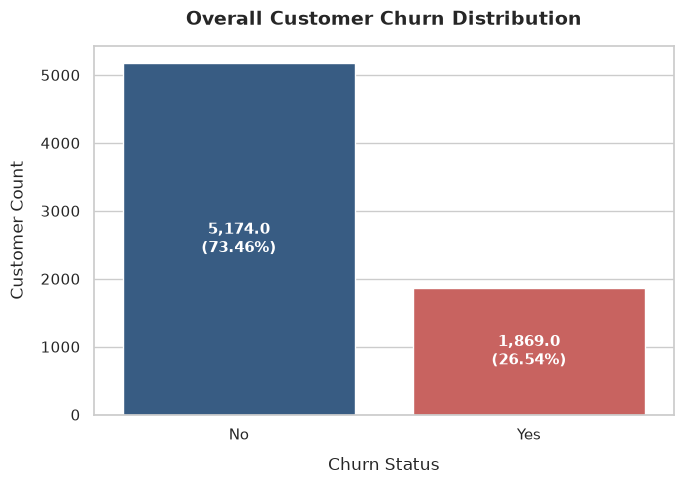

In [2]:
# Chart 1: Overall Churn Distribution
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x='Churn', palette=['#2b5c8f', '#d9534f'])
plt.title('Overall Customer Churn Distribution', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Churn Status', fontsize=12, labelpad=10)
plt.ylabel('Customer Count', fontsize=12, labelpad=10)

total = len(df)
for p in ax.patches:
    height = p.get_height()
    pct = (height / total) * 100
    ax.annotate(f'{height:,}\n({pct:.2f}%)',
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

### Interpretation: Overall Churn Distribution
- Out of **7,043 total customers**, **5,174 (73.46%)** did not churn, while **1,869 (26.54%)** churned.
- The baseline churn rate is **26.54%**, demonstrating moderate class imbalance that must be addressed during model evaluation (e.g., using ROC-AUC, F1-score, or SMOTE/class weighting).

---

C:\Users\lokna\AppData\Local\Temp\ipykernel_32892\1082016660.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=contract_churn, x='Contract', y='ChurnRate', palette='Reds_r')


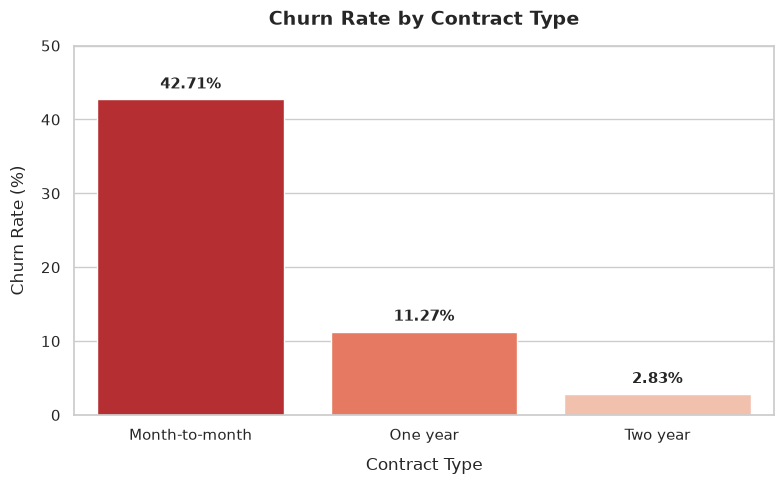

In [3]:
# Chart 2: Churn Rate by Contract Type
contract_churn = df.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
contract_churn.columns = ['Contract', 'ChurnRate']

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=contract_churn, x='Contract', y='ChurnRate', palette='Reds_r')
plt.title('Churn Rate by Contract Type', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Contract Type', fontsize=12, labelpad=10)
plt.ylabel('Churn Rate (%)', fontsize=12, labelpad=10)
plt.ylim(0, 50)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height + 1),
                ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

### Interpretation: Churn Rate by Contract Type
- **Month-to-month contract churn (~42.71%)** is drastically higher than **Two-year contract churn (~2.83%)** and **One-year contract churn (~11.27%)**.
- Customers on Month-to-month contracts churn at more than **15x the rate** of customers committed to two-year contracts, proving contract length to be one of the single strongest predictors of retention.

---

C:\Users\lokna\AppData\Local\Temp\ipykernel_32892\1619780102.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=internet_churn, x='InternetService', y='ChurnRate', palette='Oranges_r')


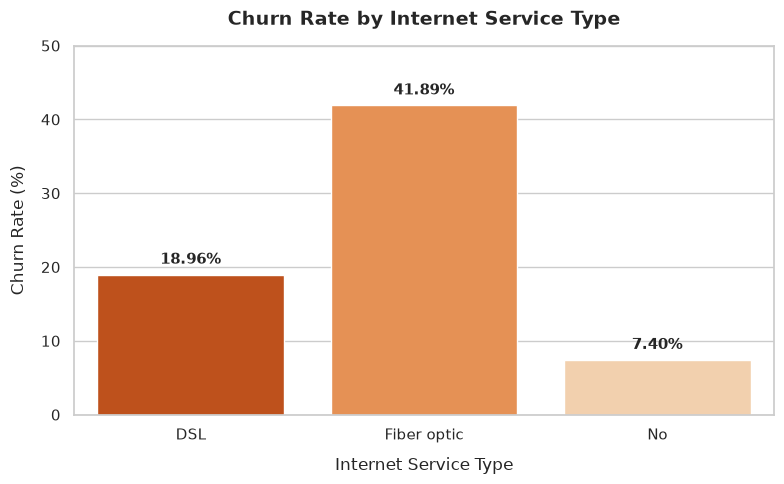

In [4]:
# Chart 3: Churn Rate by InternetService Type
internet_churn = df.groupby('InternetService')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
internet_churn.columns = ['InternetService', 'ChurnRate']

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=internet_churn, x='InternetService', y='ChurnRate', palette='Oranges_r')
plt.title('Churn Rate by Internet Service Type', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Internet Service Type', fontsize=12, labelpad=10)
plt.ylabel('Churn Rate (%)', fontsize=12, labelpad=10)
plt.ylim(0, 50)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height + 1),
                ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

### Interpretation: Churn Rate by Internet Service Type
- Customers with **Fiber optic** internet service exhibit a very high churn rate of **41.89%**.
- In contrast, **DSL** customers churn at **18.96%**, and customers with **No internet service** churn at only **7.40%**.
- The elevated churn among Fiber optic users suggests potential dissatisfaction with pricing, bill shocks, or service reliability despite higher bandwidth.

---

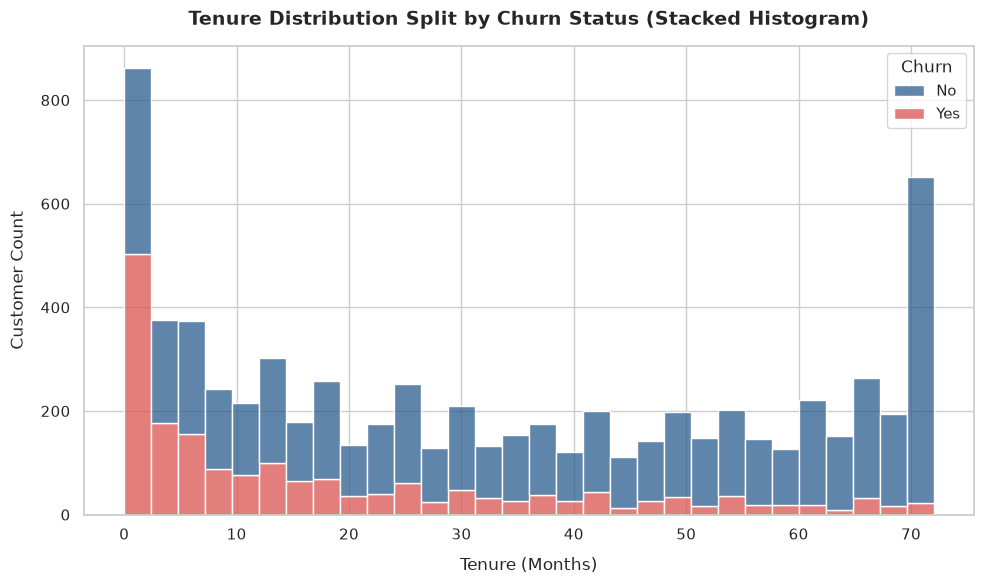

In [5]:
# Chart 4: Tenure Distribution Split by Churn (Stacked Histogram, 30 Bins)
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', bins=30, palette=['#2b5c8f', '#d9534f'])
plt.title('Tenure Distribution Split by Churn Status (Stacked Histogram)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tenure (Months)', fontsize=12, labelpad=10)
plt.ylabel('Customer Count', fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()

### Interpretation: Tenure Distribution Split by Churn
- Churn is heavily concentrated in the **first 0 to 12 months** of customer tenure, where the red 'Churned' volume dominates the total count.
- Beyond 24 months, churn drops significantly. Customers reaching **60-72 months** of tenure demonstrate strong brand loyalty with minimal churn.

---

C:\Users\lokna\AppData\Local\Temp\ipykernel_32892\2345803686.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette=['#2b5c8f', '#d9534f'], width=0.4)


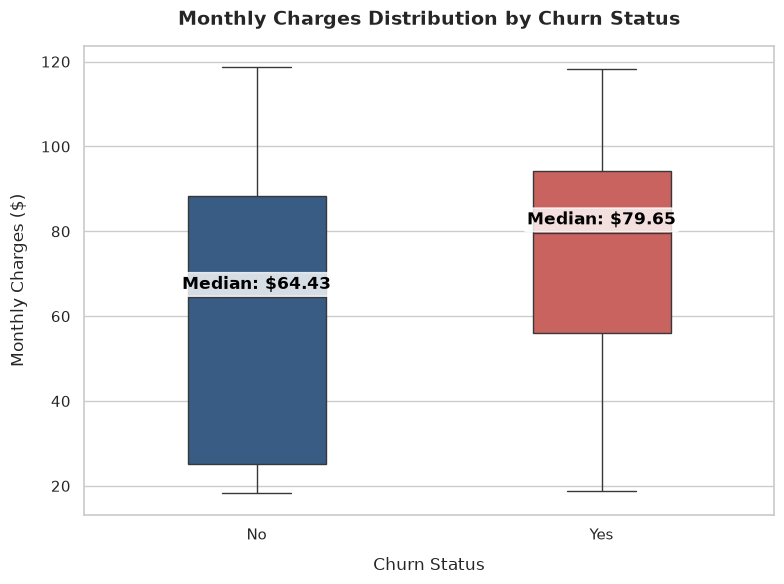

In [6]:
# Chart 5: MonthlyCharges Boxplot by Churn Status
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette=['#2b5c8f', '#d9534f'], width=0.4)
plt.title('Monthly Charges Distribution by Churn Status', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Churn Status', fontsize=12, labelpad=10)
plt.ylabel('Monthly Charges ($)', fontsize=12, labelpad=10)

# Calculate medians for annotation
medians = df.groupby('Churn')['MonthlyCharges'].median()
for i, (status, median_val) in enumerate(medians.items()):
    plt.text(i, median_val + 2, f'Median: ${median_val:.2f}', ha='center', fontweight='bold', color='black', bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

### Interpretation: MonthlyCharges Boxplot by Churn Status
- Customers who churned have a significantly higher median monthly charge (**$79.65**) compared to customers who stayed (**$64.42**).
- The 75th percentile for churned customers approaches **$95/month**, showing that higher monthly bills directly correlate with increased customer attrition.

---

C:\Users\lokna\AppData\Local\Temp\ipykernel_32892\3940301007.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=payment_churn, x='PaymentMethod', y='ChurnRate', palette='Purples_r')


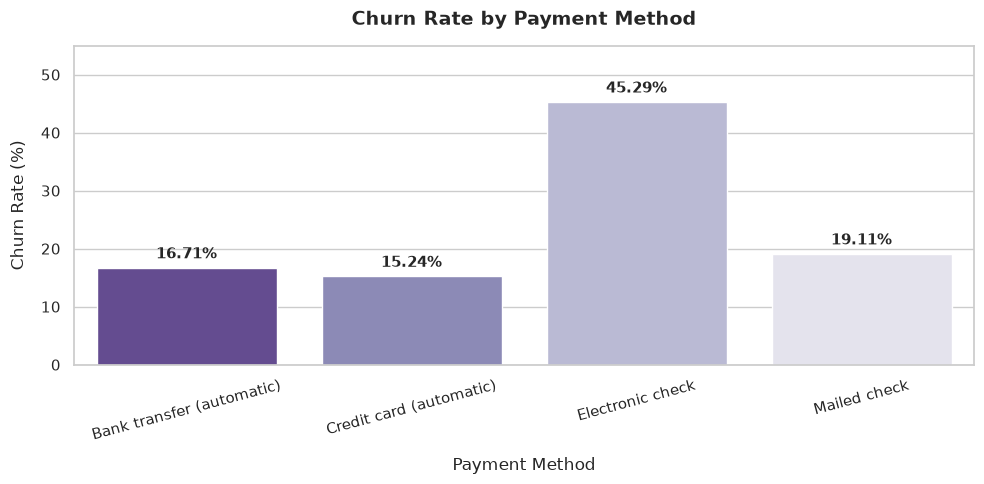

In [7]:
# Chart 6: Churn Rate by PaymentMethod
payment_churn = df.groupby('PaymentMethod')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
payment_churn.columns = ['PaymentMethod', 'ChurnRate']

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=payment_churn, x='PaymentMethod', y='ChurnRate', palette='Purples_r')
plt.title('Churn Rate by Payment Method', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Payment Method', fontsize=12, labelpad=10)
plt.ylabel('Churn Rate (%)', fontsize=12, labelpad=10)
plt.ylim(0, 55)
plt.xticks(rotation=15)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height + 1),
                ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

### Interpretation: Churn Rate by Payment Method
- Customers paying via **Electronic check** experience the highest churn rate at **45.29%**.
- Customers utilizing automatic payment options (**Bank transfer: 16.71%**, **Credit card: 15.24%**) or **Mailed check (19.11%)** churn at nearly **1/3 the rate** of Electronic check users.

---

C:\Users\lokna\AppData\Local\Temp\ipykernel_32892\2225525799.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=service_churn, x='num_services', y='ChurnRate', palette='Blues_r')


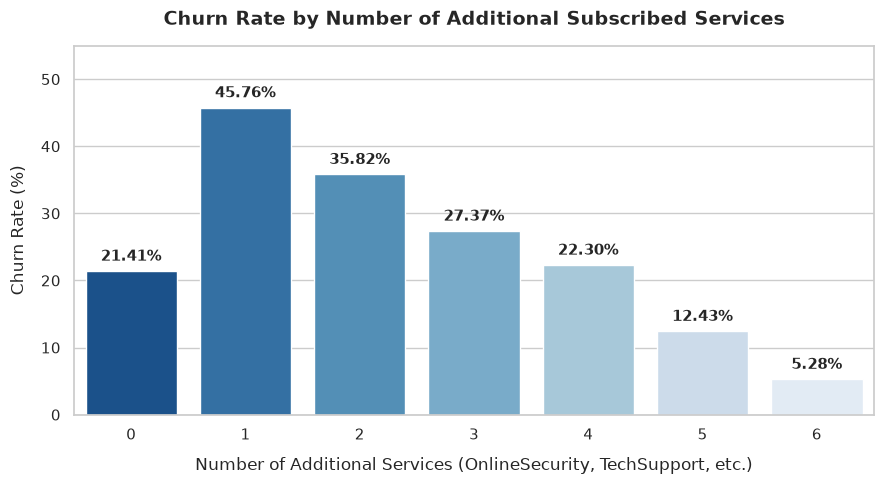

In [8]:
# Chart 7: Churn Rate by Number of Additional Services Subscribed
services = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df['num_services'] = (df[services] == 'Yes').sum(axis=1)

service_churn = df.groupby('num_services')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
service_churn.columns = ['num_services', 'ChurnRate']

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=service_churn, x='num_services', y='ChurnRate', palette='Blues_r')
plt.title('Churn Rate by Number of Additional Subscribed Services', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Number of Additional Services (OnlineSecurity, TechSupport, etc.)', fontsize=12, labelpad=10)
plt.ylabel('Churn Rate (%)', fontsize=12, labelpad=10)
plt.ylim(0, 55)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height + 1),
                ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

### Interpretation: Churn Rate by Number of Additional Services
- Among customers with internet service, churn rate decreases steadily as the number of add-on services increases: from **45.76%** (1 service) down to **5.28%** (6 services).
- Note: Customers with 0 services have a churn rate of **21.41%** primarily because this group includes all customers with No Internet Service (who have an overall low 7.4% churn rate).
- Subscribing to multiple ecosystem products (e.g., Tech Support + Online Backup + Security) significantly increases customer lock-in and product stickiness.

---

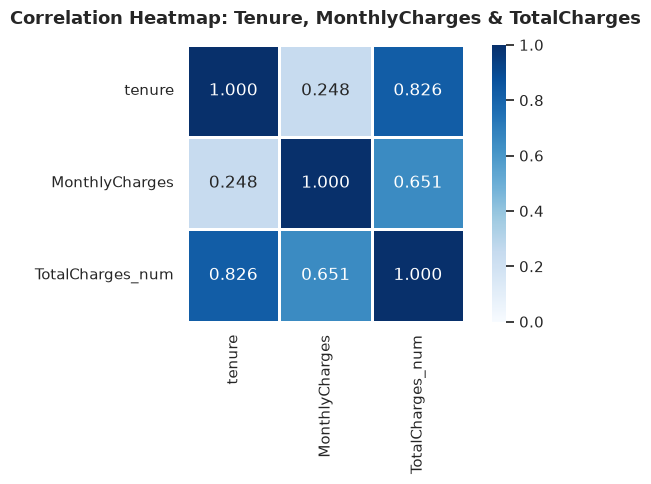

In [9]:
# Chart 8: Correlation Heatmap (tenure, MonthlyCharges, TotalCharges_num)
corr_matrix = df[['tenure', 'MonthlyCharges', 'TotalCharges_num']].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='Blues', vmin=0, vmax=1, square=True, linewidths=1)
plt.title('Correlation Heatmap: Tenure, MonthlyCharges & TotalCharges', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### Interpretation: Correlation Heatmap
- **`tenure` and `TotalCharges_num`** exhibit a very strong positive correlation (**r = 0.826**), as cumulative billing naturally grows with account age.
- **`MonthlyCharges` and `TotalCharges_num`** share a strong positive correlation (**r = 0.651**).
- **`tenure` and `MonthlyCharges`** show a weak positive correlation (**r = 0.248**), indicating that long-tenured customers tend to subscribe to slightly higher tier packages over time.

---

C:\Users\lokna\AppData\Local\Temp\ipykernel_32892\2082331176.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sub_df, x=col, y='ChurnRate', ax=ax, palette='Set2')
C:\Users\lokna\AppData\Local\Temp\ipykernel_32892\2082331176.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sub_df, x=col, y='ChurnRate', ax=ax, palette='Set2')
C:\Users\lokna\AppData\Local\Temp\ipykernel_32892\2082331176.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sub_df, x=col, y='ChurnRate', ax=ax, palette='Set2')
C:\Users\lokna\AppData\Local\Te

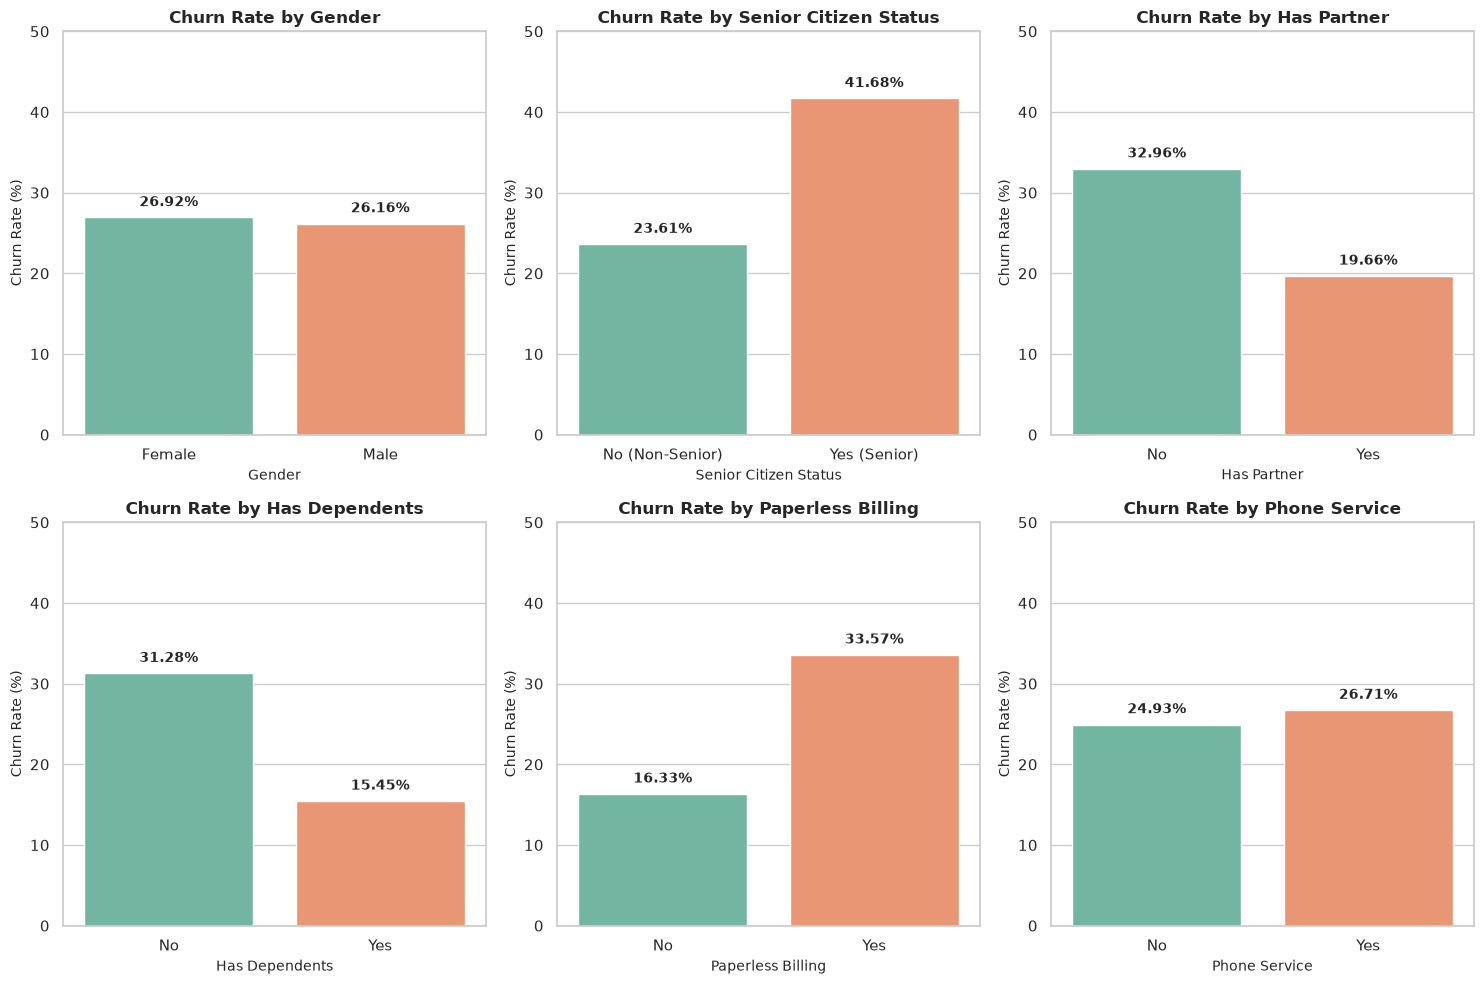

In [10]:
# Chart 9: 2x3 Grid of Percentage-Churn Bar Charts for Demographic & Billing Attributes
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
demo_cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PaperlessBilling', 'PhoneService']
titles = ['Gender', 'Senior Citizen Status', 'Has Partner', 'Has Dependents', 'Paperless Billing', 'Phone Service']

for idx, (col, title) in enumerate(zip(demo_cols, titles)):
    row = idx // 3
    col_idx = idx % 3
    ax = axes[row, col_idx]
    
    sub_df = df.groupby(col)['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
    sub_df.columns = [col, 'ChurnRate']
    
    # Convert binary indicator to readable labels if SeniorCitizen
    if col == 'SeniorCitizen':
        sub_df[col] = sub_df[col].map({0: 'No (Non-Senior)', 1: 'Yes (Senior)'})
        
    sns.barplot(data=sub_df, x=col, y='ChurnRate', ax=ax, palette='Set2')
    ax.set_title(f'Churn Rate by {title}', fontsize=12, fontweight='bold')
    ax.set_xlabel(title, fontsize=10)
    ax.set_ylabel('Churn Rate (%)', fontsize=10)
    ax.set_ylim(0, 50)
    
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{height:.2f}%',
                    (p.get_x() + p.get_width() / 2., height + 1),
                    ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

### Interpretation: Demographic & Billing Attributes Grid
1. **Gender**: Virtually no difference in churn between Female (**26.92%**) and Male (**26.16%**).
2. **Senior Citizen**: Senior Citizens churn at **41.68%** compared to **23.61%** for non-seniors.
3. **Partner Status**: Customers without a partner churn significantly more (**32.96%**) than those with a partner (**19.66%**).
4. **Dependents**: Customers without dependents churn at **31.28%**, whereas customers with dependents churn at **15.45%**.
5. **Paperless Billing**: Customers enrolled in Paperless Billing churn at double the rate (**33.57%**) of those with paper billing (**16.33%**).
6. **Phone Service**: Has minimal effect on churn rate (**26.71%** for Yes vs **24.93%** for No).

---

## Key Findings & Data-Driven Insights

1. **Contract Type as Primary Churn Driver**: Month-to-month contracts experience a **42.71%** churn rate compared to **2.83%** for two-year contracts and **11.27%** for one-year contracts. Transitioning short-term customers to long-term contracts is the most high-impact retention strategy.
2. **Fiber Optic Service Vulnerability**: Customers subscribing to Fiber Optic internet churn at **41.89%**, over double the rate of DSL users (**18.96%**). Fiber customers also report higher monthly charges, pointing to potential pricing friction or service quality mismatch.
3. **Payment Method & Electronic Check Risk**: Electronic check users have a **45.29%** churn rate, whereas automated credit card (**15.24%**) and bank transfer (**16.71%**) users show low churn. Encouraging automated billing could directly lower attrition.
4. **Early Tenure Vulnerability Window**: The highest concentration of churn occurs within the first **0–12 months** of tenure. Retention campaigns must focus on onboarding during the first year.
5. **Service Ecosystem Lock-in**: Churn drops progressively from **45.76%** for customers with 1 add-on service down to **5.28%** for customers with 6 add-on services (OnlineSecurity, TechSupport, etc.). Bundling add-on security and support services increases customer stickiness.
6. **Demographic & Billing Risk Factors**: Senior citizens (**41.68%** churn), single customers without partners (**32.96%** churn), and paperless billing subscribers (**33.57%** churn) represent higher risk customer segments requiring targeted retention programs.